In [1]:
import numpy as np
import pandas as pd
from scipy.stats import multivariate_normal

from sklearn.mixture import GaussianMixture     # Scikit-Learn library for 
from initializer import *

In [2]:
class GMMPredictionResults:
    def __init__(self, probabilities, component, component_scores):
        self.probabilities = probabilities
        self.component = component
        self.component_scores = component_scores


class GMMParameters:
    def __init__(self, means, covariances, weights, probabilities, log_likelihood):
        self.means = means
        self.covariances = covariances
        self.weights = weights
        self.probabilities = probabilities
        self.log_likelihood = log_likelihood

In [3]:
class CustomGMM:
    def __init__(self, n_components, initializer=None, max_iter=200, covariance_type='full'):
        self.n_components = n_components
        self.initializer = initializer
        self.max_iter = max_iter
        self.covariance_type = covariance_type
        self.tol = 1e-3

        # Model parameters
        self.means = None
        self.covariances = None
        self.weights = None
        self.responsibilities = None
        self.log_likelihood = None
        self.n_iter = None
        self.converged = None


    def fit(self, X, initializer=None, verbose=False):
        if hasattr(X, "to_numpy"):
            X = X.to_numpy()
        n_samples, n_features = X.shape

        if self.initializer is not None:
            params = initializer(X, self.n_components)

            self.means = params['means']
            self.covariances = params['covariances']
            self.weights = params['weights']
            self.responsibilities = params['responsibilities']
        
        else:
            indices = np.linspace(0, n_samples - 1, self.n_components, dtype=int)

            self.means =  X[indices].copy()
            self.covariances =  np.array([np.eye(n_features) for _ in range(self.n_components)])
            self.weights =  np.ones(self.n_components) / self.n_components
            self.responsibilities =  np.zeros((n_samples, self.n_components))

        self.log_likelihood = -np.inf
        self.converged = False

        for iteration in range(self.max_iter):
            new_log_likelihood = self.expectation_step(X)

            if abs(new_log_likelihood - self.log_likelihood) < self.tol:
                self.converged = True
                break
            self.log_likelihood = new_log_likelihood

            self.maximization_step(X)
            if verbose:
                print(f"Iteration {iteration}, Log-likelihood: {self.log_likelihood:.4f}")

        self.n_iter = iteration
        print(f"Converged after {iteration} iterations" if self.converged else f"Reached max iterations ({self.max_iter})")
        print(f"Log-likelihood: {self.log_likelihood:.4f}")
        return self


    def expectation_step(self, X):
        responsibilities = np.zeros((X.shape[0], self.n_components))

        for k in range(self.n_components):
            try:
                responsibilities[:, k] = self.weights[k] * multivariate_normal.pdf(X, mean=self.means[k], cov=self.covariances[k], allow_singular=True)
            except:
                responsibilities[:, k] = self.weights[k] * 1e-10

        sum_responsibilities = responsibilities.sum(axis=1, keepdims=True)
        sum_responsibilities[sum_responsibilities == 0] = 1e-10
        responsibilities /= sum_responsibilities

        log_likelihood = np.sum(np.log(sum_responsibilities))
        self.responsibilities = responsibilities
        return log_likelihood


    def maximization_step(self, X):
        n_samples, n_features = X.shape
        N_k = self.responsibilities.sum(axis=0)

        # Weights update
        self.weights = N_k / n_samples

        # Means update
        new_means = np.zeros((self.n_components, n_features))
        for k in range(self.n_components):
            if N_k[k] > 0:
                new_means[k] = (self.responsibilities[:, k:k+1] * X).sum(axis=0) / N_k[k]
        self.means = new_means

        # Covariances update
        new_covariances = np.zeros((self.n_components, n_features, n_features))
        for k in range(self.n_components):
            if N_k[k] > 0:
                diff = X - self.means[k]

                if self.covariance_type == 'full':
                    new_covariances[k] = np.dot((self.responsibilities[:, k:k+1] * diff).T, diff) / N_k[k]
                    new_covariances[k] += 1e-6 * np.eye(n_features)  # regularization

                elif self.covariance_type == 'diag':
                    cov_diag = np.sum(self.responsibilities[:, k:k+1] * (diff**2), axis=0) / N_k[k]
                    new_covariances[k] = np.diag(cov_diag + 1e-6)
        self.covariances = new_covariances


    def generate_samples(self, n_samples):
        component_indices = np.random.choice(
            self.n_components,
            size=n_samples,
            p=self.weights)

        samples = np.array([np.random.multivariate_normal(self.means[k], self.covariances[k]) for k in component_indices])
        return samples, component_indices

    
    def predict(self, X):
        if hasattr(X, "to_numpy"):
            X = X.to_numpy()

        probabilities = np.zeros((X.shape[0], self.n_components))

        for k in range(self.n_components):
            probabilities[:, k] = self.weights[k] * multivariate_normal.pdf(X, self.means[k], self.covariances[k], allow_singular=True)

        probabilities /= probabilities.sum(axis=1, keepdims=True)
        component_scores = np.max(probabilities, axis=1)
        component = np.argmax(probabilities, axis=1)
        
        return GMMPredictionResults(probabilities, component, component_scores)


    def get_params(self):
        return GMMParameters(self.means, self.covariances, self.weights, self.responsibilities, self.log_likelihood)

In [4]:
X = pd.read_csv("data/double_helix_data_1000.csv")

model = CustomGMM(n_components=48)
gmm = model.fit(X, initializer=even_spaced_initializer, verbose=True)

Iteration 0, Log-likelihood: -10013.5540
Iteration 1, Log-likelihood: -7866.7563
Iteration 2, Log-likelihood: -7831.8414
Iteration 3, Log-likelihood: -7813.1592
Iteration 4, Log-likelihood: -7796.9198
Iteration 5, Log-likelihood: -7782.1807
Iteration 6, Log-likelihood: -7771.8789
Iteration 7, Log-likelihood: -7765.4707
Iteration 8, Log-likelihood: -7760.4795
Iteration 9, Log-likelihood: -7756.3409
Iteration 10, Log-likelihood: -7753.6246
Iteration 11, Log-likelihood: -7751.8716
Iteration 12, Log-likelihood: -7750.5176
Iteration 13, Log-likelihood: -7749.0372
Iteration 14, Log-likelihood: -7747.2454
Iteration 15, Log-likelihood: -7745.8518
Iteration 16, Log-likelihood: -7745.0154
Iteration 17, Log-likelihood: -7744.3910
Iteration 18, Log-likelihood: -7743.7485
Iteration 19, Log-likelihood: -7742.7337
Iteration 20, Log-likelihood: -7741.0547
Iteration 21, Log-likelihood: -7739.9505
Iteration 22, Log-likelihood: -7739.6204
Iteration 23, Log-likelihood: -7739.3401
Iteration 24, Log-likelih

In [5]:
samples, components = gmm.generate_samples(1000)
print("Example of first 10 samples:\n", samples[:10])
print("Example of last 10 components:\n", components[-10:])

Example of first 10 samples:
 [[ 5.72497857 -7.57736794 36.03243108]
 [-9.82449629  2.2764321  39.48744127]
 [-9.86968262  0.28214689 38.96708274]
 [ 2.34164754  9.50072937 68.13346275]
 [ 9.23432745 -4.38329709 57.49395568]
 [-5.28489303  8.66331485 33.45774471]
 [-5.61964558  8.19986419 74.04838235]
 [-5.08132685  9.22236249 53.95352659]
 [-9.43481384 -1.13188254 20.28591508]
 [-9.22249447 -2.89013836  1.21529438]]
Example of last 10 components:
 [45 23 10 34 35 15  9 45 45 41]


In [6]:
gmm_parameters = gmm.get_params()
print("Means of first 10 samples:\n", gmm_parameters.means[:10])

Means of first 10 samples:
 [[ 9.63942524  1.32392098  0.61551056]
 [ 8.86348738  4.64958291  2.89976983]
 [ 4.84932305  8.48089519  7.07667061]
 [-1.17934321  9.74896446 10.44434609]
 [-5.89528097  7.60892328 13.49094961]
 [-9.27993908  2.97754746 18.64643633]
 [-9.04238279 -3.0563531  21.58117717]
 [-6.8787751  -6.78909698 24.98830059]
 [-2.85017112 -9.54205555 28.49355591]
 [ 2.36502566 -9.85840524 31.28477948]]


In [7]:
predictions = gmm.predict(samples)
predictions.component_scores[:10]       # Return scores from the first 10 samples

array([0.99963394, 0.99955439, 0.99824624, 0.97670887, 0.99725358,
       0.99989497, 0.96465518, 0.72380721, 0.97858052, 0.99530603])

### Comparison with Scikit-Learn

In [8]:
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sklearn.mixture import GaussianMixture

In [9]:
# Scikit-Learn Library GMM
""" This is purposed to compare the manual construction (using Numpy) with the optimum model with Sklearn"""
""" The result of both models should approximately be similar, therefore the manual implementation is expected to follow the result of Scikit-Learn"""

K = 48   # number of mixture components
gmm_ = GaussianMixture(
    n_components=K,
    covariance_type='full',
    max_iter=200)
gmm_.fit(X)

n_samples = 1000
new_data, _ = gmm_.sample(n_samples)

c:\Users\rhaka\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\rhaka\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\rhaka\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\rhaka\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

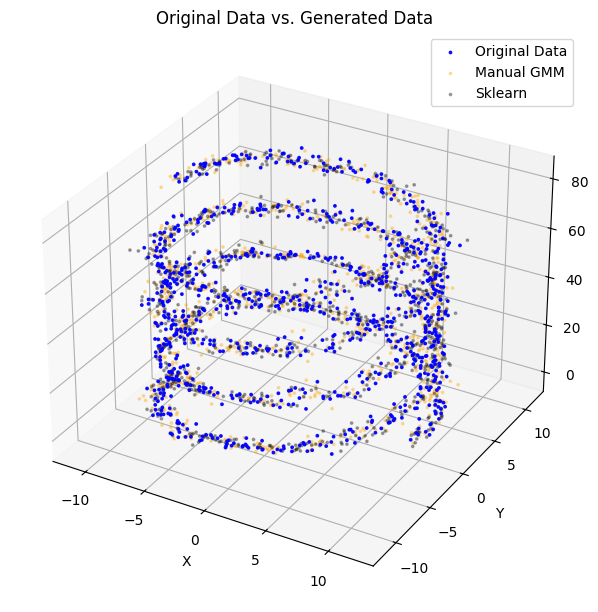

In [10]:
X = np.array(X)

fig = plt.figure(figsize=(6, 12))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X[:, 0], X[:, 1], X[:, 2],
    s=3,
    c='blue',
    alpha=0.9,
    label='Original Data')

ax.scatter(
    samples[:, 0], samples[:, 1], samples[:, 2],
    s=3,
    c='orange',
    alpha=0.3,
    label='Manual GMM')

ax.scatter(
    new_data[:, 0], new_data[:, 1], new_data[:, 2],
    s=3,
    c='black',
    alpha=0.3,
    label='Sklearn')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Original Data vs. Generated Data')

ax.legend()
plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

X = np.array(X)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

# Original Data
ax.scatter(
    X[:, 0], X[:, 1], X[:, 2],
    s=3, c='blue', alpha=0.9,
    label='Original Data'
)

# Manual GMM
ax.scatter(
    samples[:, 0], samples[:, 1], samples[:, 2],
    s=3, c='orange', alpha=0.3,
    label='Manual GMM'
)

# Sklearn
ax.scatter(
    new_data[:, 0], new_data[:, 1], new_data[:, 2],
    s=3, c='black', alpha=0.3,
    label='Sklearn'
)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Original Data vs. Generated Data')
ax.legend()

# Keep the same axis limits for every frame
ax.set_xlim(ax.get_xlim())
ax.set_ylim(ax.get_ylim())
ax.set_zlim(ax.get_zlim())


# Subtle dashed 3D grid
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis._axinfo["grid"]["color"] = (0.5, 0.5, 0.5, 0.5)
    axis._axinfo["grid"]["linestyle"] = "--"
    axis._axinfo["grid"]["linewidth"] = 0.6


plt.tight_layout()

# Rotate the viewing angle
def rotate(angle):
    ax.view_init(elev=25, azim=angle)

ani = FuncAnimation(
    fig,
    rotate,
    frames=np.arange(0, 360, 3),
    interval=40,
    repeat=True
)

# Save as a looping animated GIF
ani.save(
    'rotating_3d_plot.gif',
    writer=PillowWriter(fps=20),
    dpi=100
)

plt.close(fig)

print("GIF saved as rotating_3d_plot.gif")


GIF saved as rotating_3d_plot.gif
